# E4 failure analysis
This notebook rebuilds the four cached prediction variants on the test split.
It produces question-level evidence diagnostics and passage exports for inspection without new model calls.


## Rebuild and reconcile
Loads the cached contexts, scores, predictions, thresholds, and gold answers.
The copied E3 helpers come from cells 3, 5, 9, 11, and 17 of E3_ablation.ipynb.


In [1]:
from pathlib import Path
import hashlib, json
from collections import Counter, defaultdict
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "E2_Qwen_F1").exists():
    REPO_ROOT = REPO_ROOT.parent
E2_RESULTS = REPO_ROOT / "E2_Qwen_F1" / "results_e2_qwen_f1"
E3_RESULTS = REPO_ROOT / "E3_Ablation" / "results_e3_ablation"
E4_RESULTS = REPO_ROOT / "E4_Failure_Analysis" / "results_e4_failure_analysis"
E4_RESULTS.mkdir(parents=True, exist_ok=True)
def read_jsonl(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def read_json(path):
    if not path.exists():
        raise FileNotFoundError(path)
    return json.loads(path.read_text(encoding="utf-8"))

def row_key(row):
    return (row["condition"], str(row["id"]))

def context_hash(rows):
    text = "".join(json.dumps(row, ensure_ascii=False, sort_keys=True, separators=(",", ":")) + "\n" for row in rows)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

REFUSAL="I can not answer the question because of insufficient information in documents.";REFUSAL_KEY="insufficient information"
REFUSAL_PHRASES=[REFUSAL_KEY,"can not answer","cannot answer","unable to answer","cannot be answered","cannot be determined","cannot determine","does not provide","do not provide","doesn't provide","does not contain","do not contain","doesn't contain","does not specify","do not specify","doesn't specify","does not mention","do not mention","doesn't mention","not mentioned","no information","no mention","none of the provided documents","none of the documents","not explicitly","not directly"]
HEDGE_MARKERS=["likely","probably","presumably","possibly","might","suggest","infer","implied","indicating","as indicated","assume","speculat","expected to","would be","would have","though"]
def contains(pred,ans):
 pred=pred.lower();ans=[ans] if isinstance(ans,str) else ans
 for part in ans:
  alts=part if isinstance(part,list) else [part]
  if not any(str(a).lower() in pred for a in alts):return False
 return True
def reject(pred):
 p=pred.lower()
 if REFUSAL_KEY in p:return True
 if not any(x in p for x in REFUSAL_PHRASES):return False
 return not (any(x in p for x in HEDGE_MARKERS))
def summarize(name,es,pm):
 co=re=wr=0
 for e in es:
  p=pm[(name,str(e["id"]))];ok=contains(p,e["answer"]);r=reject(p) and not ok;co+=ok;re+=r;wr+=not ok and not r
 if name=="incomplete":return {"n":len(es),"rejection_rate":re/max(1,len(es))}
 return {"n":len(es),"accuracy":co/max(1,len(es)),"rejection_rate":re/max(1,len(es)),"wrong_answer":wr/max(1,len(es))}
def bal(s):return (sum(s[n]["accuracy"] for n in ("noise_0.0","noise_0.4","noise_0.8"))/3+s["incomplete"]["rejection_rate"])/2
def label(condition, pred, answer):
    if condition == "incomplete":
        return "refused" if reject(pred) else "answered"
    if contains(pred, answer):
        return "correct"
    return "rejected" if reject(pred) else "wrong"

paths = {name: E2_RESULTS / name for name in (
    "shared_contexts.jsonl", "shared_contexts_manifest.json",
    "rgb_e2_passage_scores.jsonl", "rgb_e2_e0_predictions.jsonl",
    "rgb_e2_e2_predictions.jsonl", "rgb_e2_e2_predictions.jsonl.meta.json")}
contexts = read_jsonl(paths["shared_contexts.jsonl"])
manifest = read_json(paths["shared_contexts_manifest.json"])
scores = read_jsonl(paths["rgb_e2_passage_scores.jsonl"])
e0 = read_jsonl(paths["rgb_e2_e0_predictions.jsonl"])
e2 = read_jsonl(paths["rgb_e2_e2_predictions.jsonl"])
e2_meta = read_json(paths["rgb_e2_e2_predictions.jsonl.meta.json"])
metrics = read_json(E2_RESULTS / "rgb_e2_qwen_metrics.json")
tau = metrics["abstention_threshold"]
filter_threshold = e2_meta["filter_threshold"]
assert context_hash(contexts) == manifest["sha256_canonical_jsonl"]
assert len(contexts) == 1300

# Reattach the answer fields used by the reference notebook from its RGB inputs.
def read_json_records(path):
    return [json.loads(line) for line in Path(path).read_text(encoding="utf-8").splitlines() if line.strip()]

refine = read_json_records(REPO_ROOT / "RGB" / "data" / "en_refine.json")
fact = read_json_records(REPO_ROOT / "RGB" / "data" / "en_fact.json")
answers = {}
for condition in ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete"):
    answers.update({(condition, str(row["id"])): row["answer"] for row in refine})
answers.update({("contradictory", str(row["id"])): row["answer"] for row in fact})
eval_rows = []
for row in contexts:
    item = dict(row)
    item["answer"] = answers[row_key(row)]
    eval_rows.append(item)

score_groups = defaultdict(list)
for row in scores:
    score_groups[row_key(row)].append(row)
score_groups = {k: sorted(v, key=lambda x: x["doc_idx"]) for k, v in score_groups.items()}
max_original_score = {key: max(item["score"] for item in rows) for key, rows in score_groups.items()}
e0_predictions = {(row["condition"], str(row["id"])): row["pred"] for row in e0}
e2_filter_only = {(row["condition"], str(row["id"])): row["pred"] for row in e2}
e0_abstain_only = dict(e0_predictions)
e2_full = dict(e2_filter_only)
for row in eval_rows:
    key = row_key(row)
    if max_original_score[key] < tau:
        e0_abstain_only[key] = REFUSAL
        e2_full[key] = REFUSAL
prediction_sets = {"E0": e0_predictions, "E2_filter_only": e2_filter_only,
                   "E0_abstain_only": e0_abstain_only, "E2_full": e2_full}
conditions = ("noise_0.0", "noise_0.4", "noise_0.8", "incomplete", "contradictory")
test_rows = {c: [r for r in eval_rows if r["condition"] == c and r["split"] == "test"] for c in conditions}
assert {c: len(v) for c, v in test_rows.items()} == {"noise_0.0":210,"noise_0.4":210,"noise_0.8":210,"incomplete":210,"contradictory":70}
summaries = {}
for method, predictions in prediction_sets.items():
    per_condition = {c: summarize(c, test_rows[c], predictions) for c in conditions}
    summaries[method] = {**per_condition, "balanced": bal(per_condition)}
    print(method, summaries[method])
expected_balanced = {"E0": 0.8722, "E2_filter_only": 0.9143, "E0_abstain_only": 0.8810, "E2_full": 0.9127}
for method, expected in expected_balanced.items():
    assert abs(summaries[method]["balanced"] - expected) < 1e-4

transition_rows = []
for before_name, after_name in (("E0","E2_filter_only"),("E0","E0_abstain_only"),("E2_filter_only","E2_full"),("E0","E2_full")):
    for condition in conditions:
        transitions = Counter((label(condition, prediction_sets[before_name][row_key(r)], r["answer"]),
                               label(condition, prediction_sets[after_name][row_key(r)], r["answer"])) for r in test_rows[condition])
        for (before, after), count in sorted(transitions.items()):
            transition_rows.append({"pair": f"{before_name}_to_{after_name}", "condition": condition,
                                    "label_before": before, "label_after": after, "count": count})
actual_transitions = pd.DataFrame(transition_rows, columns=["pair","condition","label_before","label_after","count"])
expected_transitions = pd.read_csv(E3_RESULTS / "e3_flip_transitions.csv")
pd.testing.assert_frame_equal(actual_transitions.reset_index(drop=True), expected_transitions.reset_index(drop=True), check_dtype=False)
print("Reconciliation with E3 passed: balanced scores and transitions match.")

def evidence_for(row, kept):
    if row["condition"] == "incomplete":
        return "n/a"
    hits = [contains(p, row["answer"]) for p in row["docs"]]
    if any(hits[i] and i in kept for i in range(len(hits))): return "kept"
    if any(hits): return "removed_only"
    return "none"



E0 {'noise_0.0': {'n': 210, 'accuracy': 0.9380952380952381, 'rejection_rate': 0.0380952380952381, 'wrong_answer': 0.023809523809523808}, 'noise_0.4': {'n': 210, 'accuracy': 0.9428571428571428, 'rejection_rate': 0.0380952380952381, 'wrong_answer': 0.01904761904761905}, 'noise_0.8': {'n': 210, 'accuracy': 0.6952380952380952, 'rejection_rate': 0.24285714285714285, 'wrong_answer': 0.06190476190476191}, 'incomplete': {'n': 210, 'rejection_rate': 0.8857142857142857}, 'contradictory': {'n': 70, 'accuracy': 0.5571428571428572, 'rejection_rate': 0.2857142857142857, 'wrong_answer': 0.15714285714285714}, 'balanced': 0.8722222222222222}
E2_filter_only {'noise_0.0': {'n': 210, 'accuracy': 0.9285714285714286, 'rejection_rate': 0.04285714285714286, 'wrong_answer': 0.02857142857142857}, 'noise_0.4': {'n': 210, 'accuracy': 0.9333333333333333, 'rejection_rate': 0.04285714285714286, 'wrong_answer': 0.023809523809523808}, 'noise_0.8': {'n': 210, 'accuracy': 0.7666666666666667, 'rejection_rate': 0.19047619

## Question-level evidence
Builds one row per test question, including filtering, score proximity, evidence, and labels.


In [2]:
qrows = []
for row in eval_rows:
    if row["split"] != "test": continue
    key = row_key(row); sr = score_groups[key]
    scores_list = [x["score"] for x in sr]
    kept = [i for i, s in enumerate(scores_list) if s >= filter_threshold]
    fallback = not kept
    if fallback: kept = [max(range(len(scores_list)), key=lambda i: scores_list[i])]
    best = max(scores_list)
    gold_in_doc = [contains(doc, row["answer"]) for doc in row["docs"]]
    d = {"condition":row["condition"],"id":row["id"],"query":row["query"],"gold_answer":row["answer"],
         "n_docs":len(row["docs"]),"scores":json.dumps(scores_list),"best_score":best,
         "kept_indices":json.dumps(kept),"n_kept":len(kept),"fallback_used":fallback,
         "below_tau":best < tau,"near_tau":tau/2 <= best < 2*tau,
         "gold_in_doc":json.dumps(gold_in_doc),"gold_evidence":evidence_for(row, kept)}
    for name, preds in prediction_sets.items():
        d[f"pred_{name}"] = preds[key]; d[f"label_{name}"] = label(row["condition"], preds[key], row["answer"])
    if row["condition"] == "contradictory":
        true_idx = next((i for i,p in enumerate(row["docs"]) if p in next(x["positive"] for x in fact if str(x["id"]) == str(row["id"]))), None)
        fake_idx = next((i for i,p in enumerate(row["docs"]) if p in next(x["positive_wrong"] for x in fact if str(x["id"]) == str(row["id"]))), None)
        d.update(true_idx=true_idx, fake_idx=fake_idx, true_kept=true_idx in kept if true_idx is not None else None,
                 fake_kept=fake_idx in kept if fake_idx is not None else None,
                 both_kept=(true_idx in kept and fake_idx in kept) if true_idx is not None and fake_idx is not None else None)
    else:
        d.update(true_idx="", fake_idx="", true_kept="", fake_kept="", both_kept="")
    qrows.append(d)
question_table = pd.DataFrame(qrows)

def category_for(r, variant):
    lab = r[f"label_{variant}"]
    if r["condition"] == "incomplete": return "answered_without_evidence" if lab == "answered" else ""
    if lab == "correct": return ""
    base = "E2_filter_only" if variant == "E2_full" else "E0"
    if r[f"label_{base}"] == "correct" and r["below_tau"] and variant == "E2_full": return "abstention_override"
    if r["gold_evidence"] == "removed_only": return "filter_removed_gold"
    if r["gold_evidence"] == "none": return "gold_not_found"
    if r["gold_evidence"] == "kept" and lab == "rejected": return "refused_despite_evidence"
    if r["gold_evidence"] == "kept" and lab == "wrong": return "wrong_despite_evidence"
    return ""

question_table["failure_category_E2_full"] = question_table.apply(lambda r: category_for(r, "E2_full"), axis=1)
question_table["failure_category_E2_filter_only"] = question_table.apply(lambda r: category_for(r, "E2_filter_only"), axis=1)
expected_e2_full_counts = {"abstention_override": 13, "answered_without_evidence": 7, "filter_removed_gold": 17, "gold_not_found": 1, "refused_despite_evidence": 69, "wrong_despite_evidence": 26}
assert question_table["failure_category_E2_full"].value_counts().reindex(expected_e2_full_counts, fill_value=0).to_dict() == expected_e2_full_counts
question_table.to_csv(E4_RESULTS / "e4_question_table.csv", index=False)


# String-match sanity checks for the gold_evidence flags.
# The "relevant" field in the score file is the RGB ground-truth positive/negative label (None for contradictory).
def doc_has_gold(s):
    r = next(r for r in eval_rows if row_key(r) == row_key(s))
    return contains(r["docs"][s["doc_idx"]], r["answer"])
pos = [s for s in scores if s["relevant"] is True]; neg = [s for s in scores if s["relevant"] is False]
print(f"RGB positive passages containing the gold string: {sum(map(doc_has_gold, pos))/len(pos):.4f}")
print(f"RGB negative passages containing the gold string: {sum(map(doc_has_gold, neg))/len(neg):.4f}")
inc_with_gold = [r["id"] for r in test_rows["incomplete"] if any(contains(p, r["answer"]) for p in r["docs"])]
print("Incomplete test questions whose negative passages contain the gold string (incidental matches):", len(inc_with_gold), inc_with_gold)
print("Answerable noise questions with no gold string in any passage:", int((question_table.condition.str.startswith("noise") & (question_table.gold_evidence == "none")).sum()))
print("Contradictory fake passage identification: exact, using RGB en_fact positive and positive_wrong text membership.")

RGB positive passages containing the gold string: 0.9978
RGB negative passages containing the gold string: 0.0067
Incomplete test questions whose negative passages contain the gold string (incidental matches): 4 [262, 269, 53, 6]
Answerable noise questions with no gold string in any passage: 1
Contradictory fake passage identification: exact, using RGB en_fact positive and positive_wrong text membership.


## Failure categories
Assigns documented rule-based categories to incorrect answerable results and answered incomplete questions.
It also writes the category counts and the E2_full stacked bar chart.


In [3]:
categories = []
for variant in ("E2_full","E2_filter_only"):
    for c in conditions:
        for cat in ("abstention_override","filter_removed_gold","gold_not_found","refused_despite_evidence","wrong_despite_evidence","answered_without_evidence"):
            categories.append({"variant":variant,"condition":c,"category":cat,
                               "count":sum(category_for(r,variant)==cat for _,r in question_table[question_table.condition==c].iterrows())})
cat_table = pd.DataFrame(categories)
cat_table.to_csv(E4_RESULTS / "e4_failure_categories.csv", index=False)
print("Rows:", len(question_table)); print(question_table.condition.value_counts().sort_index()); print(cat_table.to_string(index=False))
overrides = question_table[(question_table.label_E2_filter_only == "correct") & (question_table.label_E2_full == "rejected") & question_table.condition.isin(["noise_0.0", "noise_0.4", "noise_0.8", "contradictory"])]
print("Abstention overrides (13 expected):", len(overrides)); print(overrides.groupby(["condition", "fallback_used", "near_tau", "gold_evidence"]).size().rename("count"))
filter_losses = question_table[(question_table.label_E0 == "correct") & (question_table.label_E2_filter_only != "correct") & question_table.condition.isin(["noise_0.0", "noise_0.4", "noise_0.8", "contradictory"])]
print("E0-correct to filter-not-correct by gold_evidence:"); print(filter_losses.groupby("gold_evidence").size().rename("count"))
contradictory_flags = question_table[question_table.condition == "contradictory"]
print("Contradictory E2_full label by true/fake passage kept:"); print(pd.crosstab([contradictory_flags.true_kept, contradictory_flags.fake_kept], contradictory_flags.label_E2_full))
fact_by_id = {str(x["id"]): x for x in fact}
correct_contra = contradictory_flags[contradictory_flags.label_E2_full == "correct"]
print("Contradictory 'correct' answers that also contain the fake answer:",
      sum(contains(r.pred_E2_full, fact_by_id[str(r.id)]["fakeanswer"]) for _, r in correct_contra.iterrows()), "of", len(correct_contra))

# Decomposition of the E0 -> E2_filter_only balanced-score gain.
noise_delta = sum(summaries["E2_filter_only"][n]["accuracy"] - summaries["E0"][n]["accuracy"] for n in ("noise_0.0","noise_0.4","noise_0.8")) / 3 / 2
incomplete_delta = (summaries["E2_filter_only"]["incomplete"]["rejection_rate"] - summaries["E0"]["incomplete"]["rejection_rate"]) / 2
print(f"Balanced gain from noise accuracy: {noise_delta:.4f}; from incomplete rejection: {incomplete_delta:.4f}; total: {noise_delta + incomplete_delta:.4f}")

# Abstention changes between E2_filter_only and E2_full.
changed = question_table[question_table.pred_E2_filter_only != question_table.pred_E2_full]
print("Predictions changed by abstention:", len(changed)); print(changed.groupby(["condition", "label_E2_filter_only", "label_E2_full"]).size().rename("count"))

# Filter-removed gold: how many passages were kept and where Qwen ranked the gold passage.
removed = question_table[question_table.gold_evidence == "removed_only"]
def gold_rank(r):
    s = json.loads(r.scores); g = json.loads(r.gold_in_doc); order = sorted(range(len(s)), key=lambda i: -s[i])
    return min(order.index(i) for i in range(len(s)) if g[i]) + 1
print("Filter-removed gold: fallback used", int(removed.fallback_used.sum()), "of", len(removed), "| n_kept", removed.n_kept.value_counts().sort_index().to_dict(),
      "| best gold-passage rank", Counter(removed.apply(gold_rank, axis=1)))

# Incomplete questions still answered by E2_full.
inc_answered = question_table[(question_table.condition == "incomplete") & (question_table.label_E2_full == "answered")]
print("Incomplete answered by E2_full:", len(inc_answered), "| fallback used", int(inc_answered.fallback_used.sum()), "| below tau", int(inc_answered.below_tau.sum()))




Rows: 910
condition
contradictory     70
incomplete       210
noise_0.0        210
noise_0.4        210
noise_0.8        210
Name: count, dtype: int64
       variant     condition                  category  count
       E2_full     noise_0.0       abstention_override      0
       E2_full     noise_0.0       filter_removed_gold      1
       E2_full     noise_0.0            gold_not_found      0
       E2_full     noise_0.0  refused_despite_evidence      9
       E2_full     noise_0.0    wrong_despite_evidence      5
       E2_full     noise_0.0 answered_without_evidence      0
       E2_full     noise_0.4       abstention_override      1
       E2_full     noise_0.4       filter_removed_gold      2
       E2_full     noise_0.4            gold_not_found      0
       E2_full     noise_0.4  refused_despite_evidence      8
       E2_full     noise_0.4    wrong_despite_evidence      4
       E2_full     noise_0.4 answered_without_evidence      0
       E2_full     noise_0.8       abstenti

## Passage exports
Exports truncated passage views for the main failure groups and provides show_example for full inspection.
These files are for reference; the failure categories are assigned automatically by the rules above.

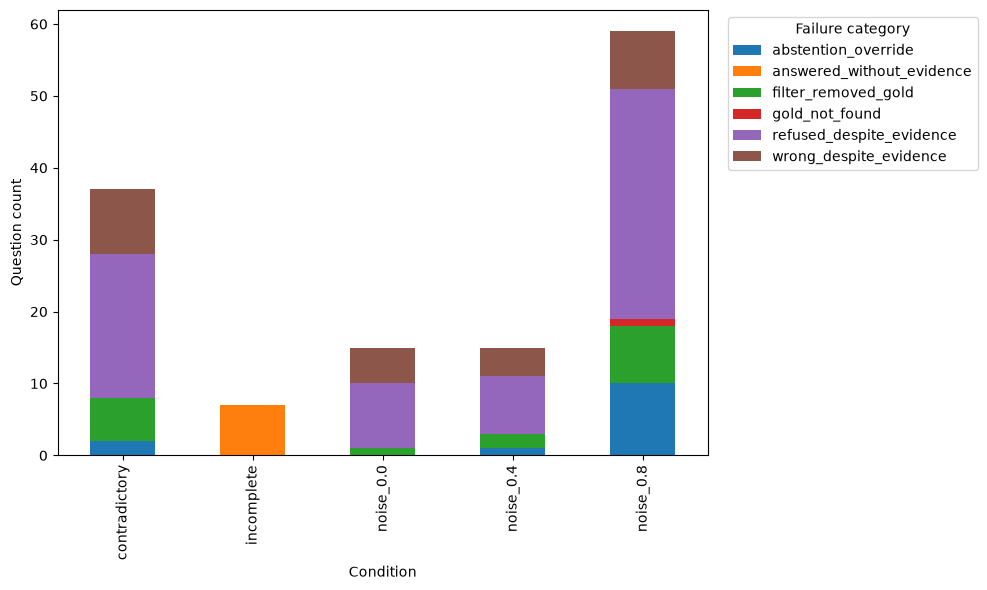

In [4]:
def reading_frame(rows):
    out = []
    for _, r in rows.iterrows():
        original = next(x for x in eval_rows if x["condition"] == r.condition and str(x["id"]) == str(r.id))
        passages = [{"score":s, "kept":i in json.loads(r.kept_indices), "text":p[:300]} for i,(p,s) in enumerate(zip(original["docs"], json.loads(r.scores)))]
        out.append({"condition":r.condition,"id":r.id,"query":r.query,"gold_answer":r.gold_answer,
                    "passages":json.dumps(passages, ensure_ascii=False),
                    "pred_E0":r.pred_E0,"pred_E2_filter_only":r.pred_E2_filter_only,
                    "pred_E0_abstain_only":r.pred_E0_abstain_only,"pred_E2_full":r.pred_E2_full,
                    "failure_category_E2_full":r.failure_category_E2_full,"failure_category_E2_filter_only":r.failure_category_E2_filter_only})
    return pd.DataFrame(out)
def show_example(condition, id):
    r = next(x for x in eval_rows if x["condition"] == condition and str(x["id"]) == str(id)); q = question_table[(question_table.condition==condition)&(question_table.id.astype(str)==str(id))].iloc[0]
    print(r["query"]); print("Gold:", r["answer"])
    for i,(p,s) in enumerate(zip(r["docs"], json.loads(q.scores))):
        print(f"\n[{i}] score={s:.12g} {'kept' if i in json.loads(q.kept_indices) else 'removed'} contains_gold={contains(p,r['answer'])}\n{p}")
    for v in prediction_sets: print(v, q[f"label_{v}"], q[f"pred_{v}"])
    print("best_score",q.best_score,"tau",tau,"filter_threshold",filter_threshold,"failure_category",q.failure_category_E2_full)
    if condition=="contradictory": print("true/fake/both kept",q.true_kept,q.fake_kept,q.both_kept)

def export(name, frame): frame.to_csv(E4_RESULTS / name, index=False)
export("e4_read_abstention_flips.csv", reading_frame(question_table[question_table.pred_E2_filter_only != question_table.pred_E2_full]))
export("e4_read_filter_losses.csv", reading_frame(question_table[(question_table.condition != "incomplete") & (question_table.label_E0=="correct") & (question_table.label_E2_filter_only!="correct")]))
gain_pool = question_table[(question_table.condition != "incomplete") & (question_table.label_E0!="correct") & (question_table.label_E2_filter_only=="correct")]
quotas = {c: 10 // len(gain_pool.condition.unique()) for c in gain_pool.condition.unique()}
for c in sorted(gain_pool.condition.unique())[:10 % len(quotas)]: quotas[c] += 1
gains = pd.concat([group.sample(n=min(quotas[c], len(group)), random_state=42) for c, group in gain_pool.groupby("condition")])
export("e4_read_filter_gains.csv", reading_frame(gains))
export("e4_read_incomplete_answered.csv", reading_frame(question_table[(question_table.condition=="incomplete") & (question_table.label_E2_full=="answered")]))
export("e4_read_contradictory_failures.csv", reading_frame(question_table[(question_table.condition=="contradictory") & (question_table.label_E2_full!="correct")]))

plot_data = cat_table[(cat_table.variant=="E2_full") & (cat_table["count"]>0)].pivot(index="condition", columns="category", values="count").fillna(0)
plot_data.plot(kind="bar", stacked=True, figsize=(10,6))
plt.xlabel("Condition"); plt.ylabel("Question count"); plt.legend(title="Failure category", bbox_to_anchor=(1.02,1), loc="upper left")
plt.tight_layout(); plt.savefig(E4_RESULTS / "e4_failure_categories.png", dpi=150); plt.show()


## Findings
All counts below are for the 910-row test split and are printed by the cells above.
### Abstention overrides
Score-based abstention changed 17 test predictions. 13 answerable questions moved from correct to rejected: 10 in noise_0.8, 1 in noise_0.4, and 2 contradictory. The other 4 changes were incomplete questions, of which 3 moved from answered to refused and 1 was already a refusal. All 13 overrides had kept a gold-bearing passage, and 9 of them were fallback cases where no passage reached the filter threshold. Losing 11 correct noise answers outweighs gaining 3 incomplete refusals in the balanced score (contradictory questions are not part of it), which explains the slight drop from 0.9143 to 0.9127. The threshold was calibrated on E0 predictions; the filter-only recalibration in E3 (`e3_tau_prime_comparison.csv`) is the relevant follow-up.
### Filter losses and gains
Filtering raised the balanced score from 0.8722 for E0 to 0.9143 for E2_filter_only. Most of the +0.0421 gain (+0.0333) comes from incomplete-question rejection rising from 0.8857 to 0.9524. Noise accuracy contributes +0.0087: noise_0.8 rises from 0.6952 to 0.7667, while noise_0.0 and noise_0.4 each fall by about 0.01. Outside the incomplete condition, 47 questions became correct and 40 E0-correct questions became not correct (15 noise_0.8, 13 contradictory, 6 each in noise_0.0 and noise_0.4). Only 10 of these 40 lost their gold passage to the filter; in the other 30 the gold passage was kept and the model still refused or answered wrongly. Across all E2 failures, gold evidence was removed in 17 questions. In 15 of these only one passage was kept, and Qwen ranked the gold passage 2nd to 5th, so the filter preferred a non-gold passage rather than discarding a high-scoring gold one.
### Evidence-retained failures
The largest E2_full failure category is refused_despite_evidence (69 of 133 categorised failures), followed by wrong_despite_evidence (26). Most remaining errors therefore happen at the generation or refusal decision with the gold passage present, not at retrieval. The single gold_not_found case (noise_0.8, Chicago P.D. S10E4) is a string-match miss rather than missing evidence: the kept passage says "Donde Vives" without the accent, and the model translated the title as "Where You Live".
### Incomplete questions answered
E2_full still answered 7 incomplete questions, compared with 10 for E2_filter_only and 24 for E0. None of the 7 used the fallback, and none fell below the abstention threshold: in each case Qwen scored at least one negative passage above both thresholds. The filter and abstention combination substantially improves refusal behaviour but cannot catch irrelevant passages that Qwen scores confidently.
### Contradictory questions
The true and fake passages could be identified exactly from the RGB data. Across the 70 contradictory test questions, the true passage was removed in 6 cases, and the fake passage was kept in 44 cases, always together with the true passage. E2_full was correct on 33, rejected 27, and wrong on 10. Accuracy is similar whether the fake passage was kept (23 of 44) or removed with the true passage kept (10 of 20), so keeping the fake passage is not by itself what drives the failures, and most failures occur with the true passage available. Under the substring metric, 4 of the 33 correct answers also name the fake answer, so contradictory accuracy is slightly lenient.
### Proposed fixes
Recalibrate the abstention threshold on the filter-only system (see E3) rather than on E0, since every override discarded a correct answer that had gold evidence. Replace the single-passage fallback with a minimum of two kept passages; this would have retained the gold passage in the 5 filter-removed cases where Qwen ranked it second. Because most failures happen with gold evidence kept, adjust the generation prompt or refusal rule so that the model answers when a kept passage supports an answer. For contradictory contexts, detect multiple competing answer-bearing passages and either report the conflict or abstain with an explicit contradiction reason. Normalise accents and diacritics in the string-match metric.